# The paper's model on correct answers, by knowledge regime

A correct answer under no knowledge is a guess. A model that reads behaviour rather than
outcome should give it a lower probability than a correct answer given with knowledge. This
notebook tests that for the paper's Study 2 model: the twelve features of
`descriptives.SHOWCASE_FEATURE_COLS`, fitted on every Study 1 trial and applied to every
Study 2 trial. It is told which answer is correct.

1. The predictions, and the mean probability per regime and answer.
2. Correct answers: the regime means and their differences, with intervals and p.
3. Each participant's own means, and the figure.

Every participant has all three regimes, so the regimes are compared within the same people:
by resampling participants, and by a Wilcoxon test on each person's own differences. Study 2
has 13 participants.

This notebook only shows. `python -m src.explorations.regime_probability.run` saves the figure
and its tables to `reports/explorations/regime_probability/`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; run.py's `main` saves

from IPython.display import display

import src.config.columns as Con
import src.explorations.regime_probability.run as P

## 1. The predictions
*`run.paper_predictions`, `run.regime_means`*

The paper's own Study 2 path (`knowledge_regimes.descriptives`): the Study 2 table, the model
fitted on Study 1, its predicted probability that the answer is correct. Then the mean and
median probability in each regime, on right answers (`is_correct` 1) and wrong ones (0).

In [2]:
preds = P.paper_predictions()
means = P.regime_means(preds)
means.round(3)

KnowQA showcase frame: 1885 trials x 201 columns
  participants : 13
  sessions     : 39
  regimes      : {'full knowledge': 640, 'no knowledge': 625, 'partial knowledge': 620}
fitted trial_level_log_reg on 19436 L1 trials, 12 features
  L1 base rate: 0.8407
imputed with fill_value=0.0: 11 cell(s) = 0.049% of the KnowQA feature matrix
    mean_max_fix_pupil_size_z__correct: 11 (0.58% of trials)


,regime,is_correct,n,mean_prob,median_prob,model_family
0,no knowledge,1,232,0.652,0.776,logreg
1,no knowledge,0,393,0.203,0.124,logreg
2,partial knowledge,1,496,0.668,0.793,logreg
3,partial knowledge,0,124,0.226,0.163,logreg
4,full knowledge,1,624,0.748,0.884,logreg
5,full knowledge,0,16,0.184,0.150,logreg


## 2. Correct answers by regime
*`run.contrast_tests`*

The first three rows are the regime means on correct answers, with 95% intervals from
resampling participants. The last three are the differences: the estimate, its interval and p,
and the per-person check -- how many of the 13 have the higher mean in the regime with more
knowledge, the median of their differences, and the Wilcoxon p.

In [3]:
tests = P.contrast_tests(preds)
tests[["test", "estimate", "ci_low", "ci_high", "p", "n_trials", "people_higher", "median_person_diff",
       "wilcoxon_p"]].round(4)

,test,estimate,ci_low,ci_high,p,n_trials,people_higher,median_person_diff,wilcoxon_p
0,no knowledge,0.6516,0.5529,0.7351,NaN,232.0,NaN,NaN,NaN
1,partial knowledge,0.6684,0.6247,0.7089,NaN,496.0,NaN,NaN,NaN
2,full knowledge,0.7484,0.6915,0.8033,NaN,624.0,NaN,NaN,NaN
3,partial - no,0.0168,-0.0573,0.0995,0.6670,NaN,6.0,-0.0416,1.0000
4,full - no,0.0968,0.0243,0.1853,0.0050,NaN,9.0,0.0604,0.0398
5,full - partial,0.0800,0.0374,0.1236,0.0005,NaN,11.0,0.0852,0.0046


## 3. Each participant
*`run.person_means`, `run.plot_correct_by_regime`*

Each person's mean probability on their correct answers in each regime, with the number of
correct answers behind it. The smallest counts are under no knowledge, where most answers are
wrong.

In [4]:
people = P.person_means(preds)
display(people.pivot(index=Con.PARTICIPANT_ID, columns=P.REGIME_COL, values="mean_prob")[list(P.REGIME_ORDER)].round(3))
display(people.pivot(index=Con.PARTICIPANT_ID, columns=P.REGIME_COL, values="n")[list(P.REGIME_ORDER)])

regime,no knowledge,partial knowledge,full knowledge
participant_id,,,
4000,0.813,0.827,0.874
4001,0.837,0.722,0.812
4002,0.572,0.530,0.574
4003,0.662,0.724,0.701
4004,0.236,0.542,0.717
4005,0.715,0.629,0.814
4006,0.741,0.658,0.682
4007,0.656,0.705,0.791
4008,0.448,0.646,0.565


regime,no knowledge,partial knowledge,full knowledge
participant_id,,,
4000,25,39,49
4001,25,39,48
4002,21,39,48
4003,19,39,47
4004,16,36,46
4005,20,31,46
4006,12,39,49
4007,15,34,50
4008,16,41,50


Grey lines are the participants, coloured points the regime means with their intervals, and
the brackets each difference with its p.

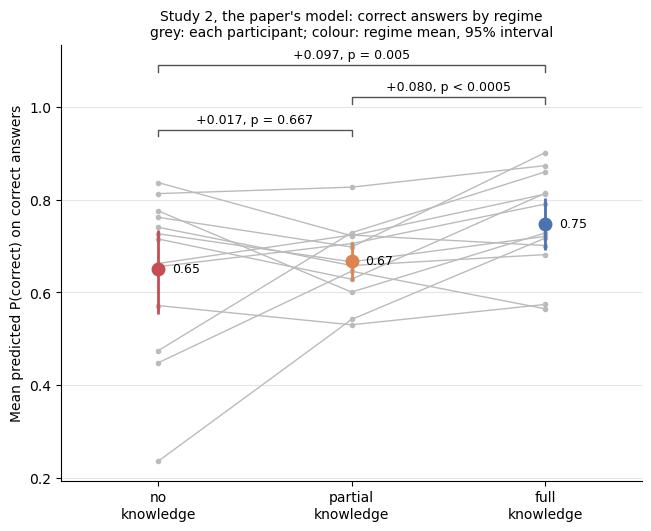

In [5]:
fig = P.plot_correct_by_regime(tests, people, means)